In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split,GridSearchCV,cross_val_score,StratifiedKFold)
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report,roc_curve,roc_auc_score)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")


In [4]:
df = pd.read_csv("diabetes.csv")

In [5]:
df.shape

(768, 9)

In [6]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [7]:
df.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [8]:
print("Column names:")
print(df.columns.tolist())

Column names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


In [9]:
print(df.dtypes)

Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object


In [10]:
missing = df.isnull().sum()
print("Missing Values:")
print(missing)

Missing Values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


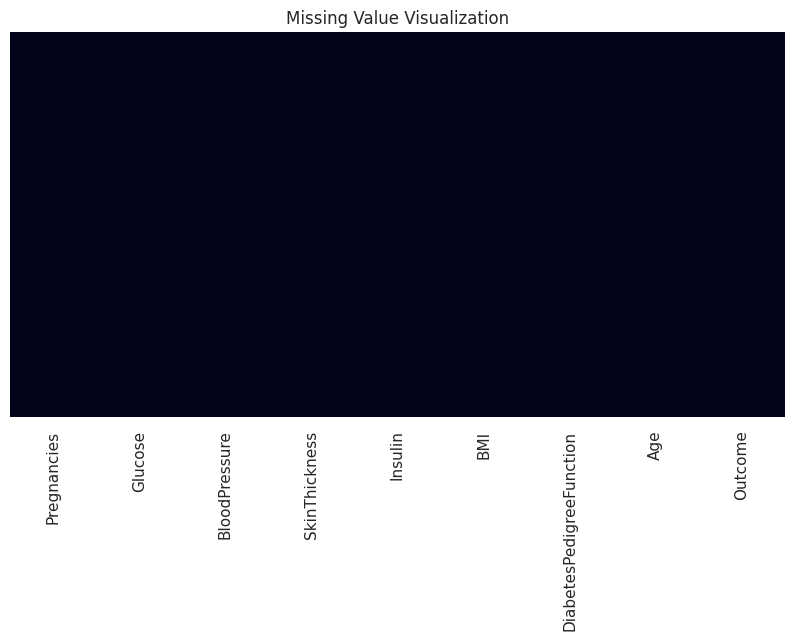

In [11]:
plt.figure(figsize=(10,5))
sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Value Visualization")
plt.show()

In [12]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:",duplicate_count)

Number of duplicate rows: 0


In [13]:
print(df["Outcome"].value_counts())

Outcome
0    500
1    268
Name: count, dtype: int64


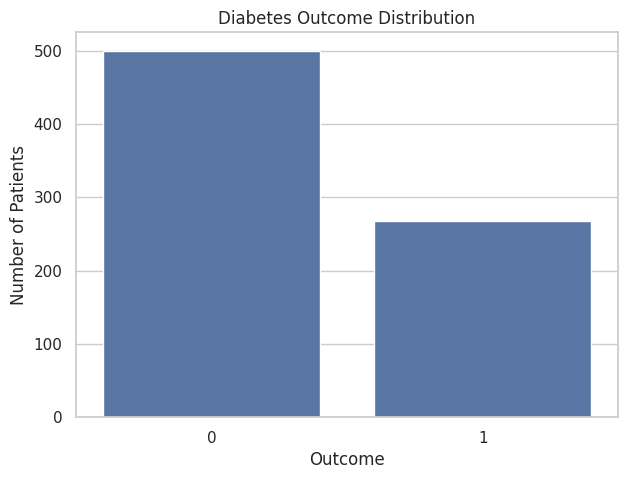

In [14]:

plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x="Outcome"
)

plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome")
plt.ylabel("Number of Patients")

plt.show()

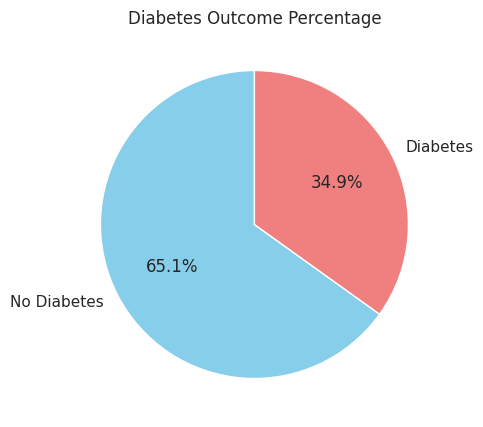

In [15]:
plt.figure(figsize=(7,5))

target_counts = df['Outcome'].value_counts()
target_percentage = target_counts / len(df) * 100

plt.pie(target_percentage, labels=['No Diabetes', 'Diabetes'], autopct='%1.1f%%',
        startangle=90,
        colors=['skyblue', 'lightcoral'])
plt.title("Diabetes Outcome Percentage")
plt.show()

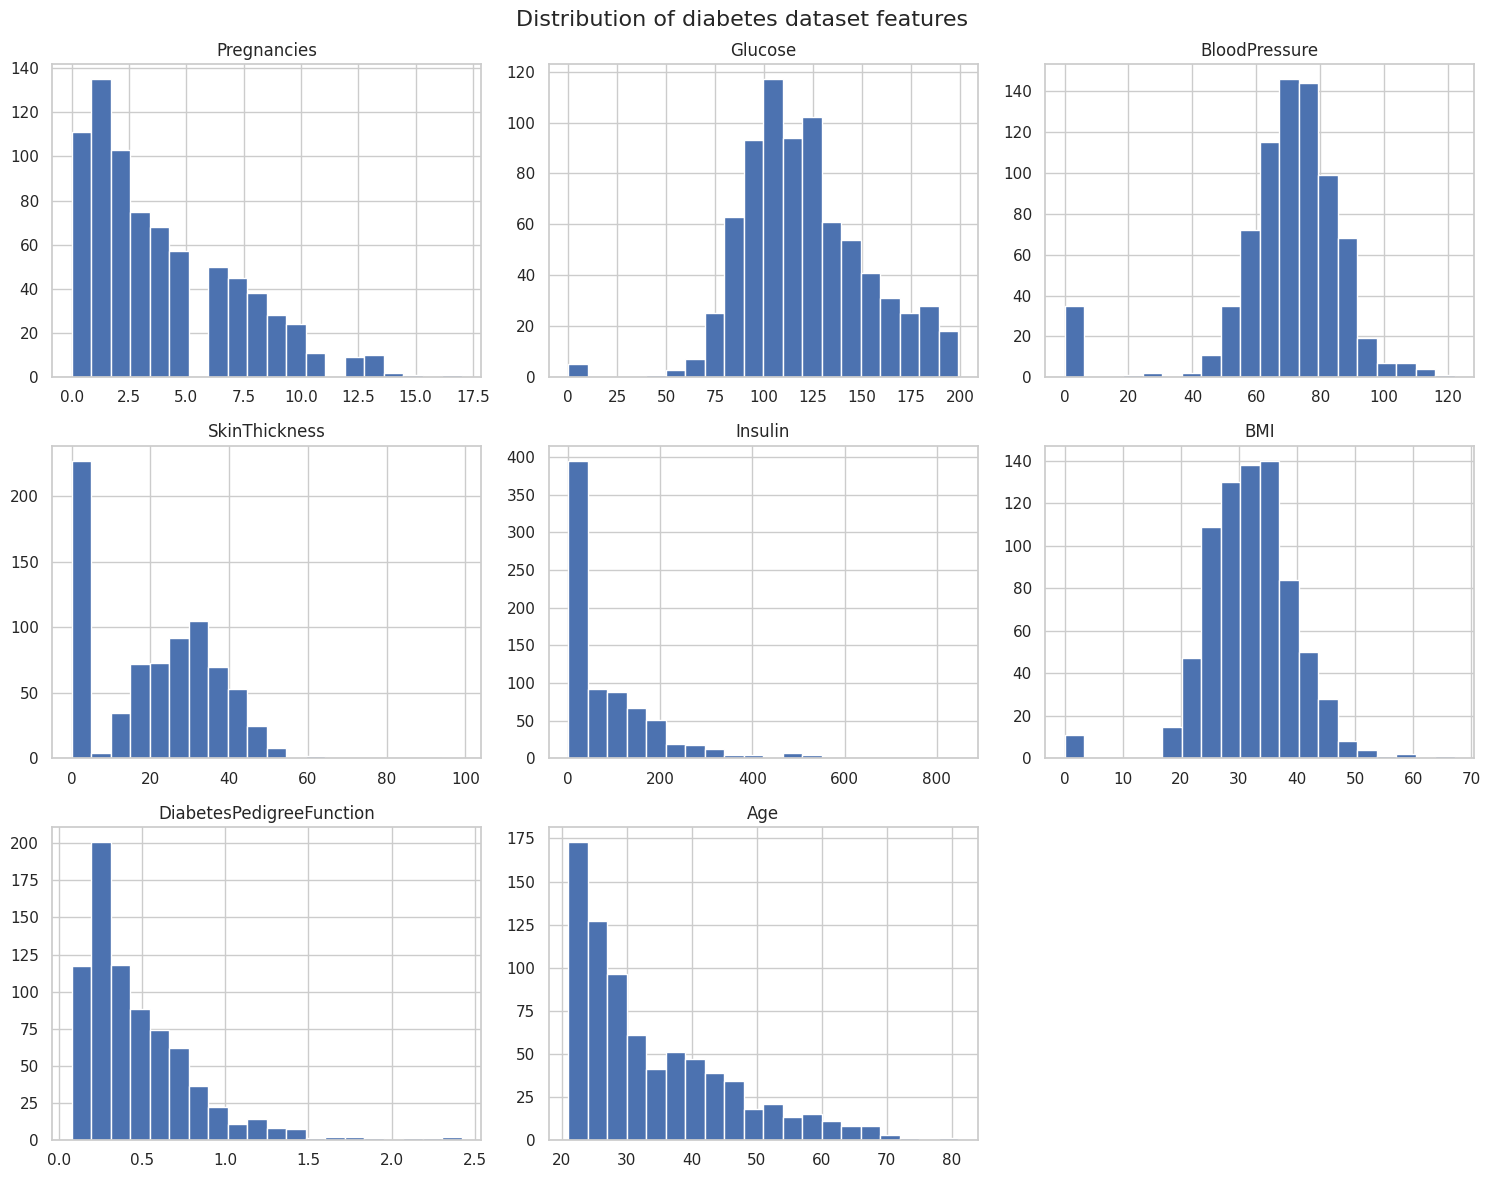

In [16]:
features = df.drop(columns="Outcome").columns

df[features].hist(figsize=(15,12),bins=20)

plt.suptitle("Distribution of diabetes dataset features",fontsize=16)

plt.tight_layout()
plt.show()

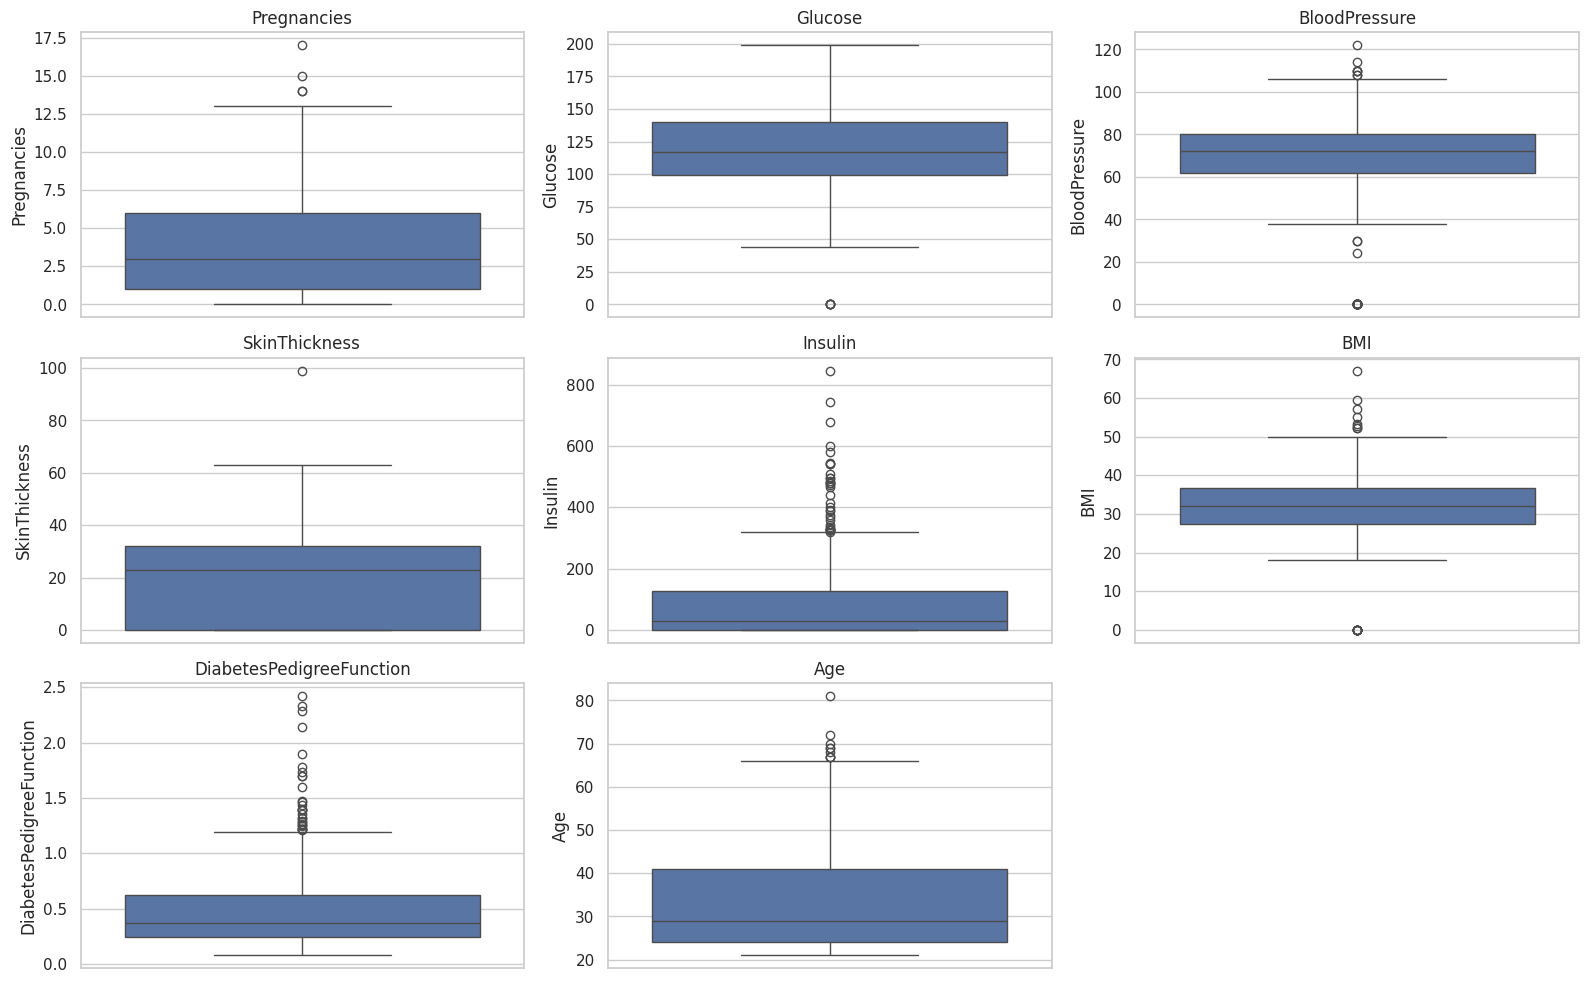

In [17]:
plt.figure(figsize=(16,10))

for i, col in enumerate(features, 1):

   plt.subplot(3,3,i)

   sns.boxplot(y=df[col])
   plt.title(col)
plt.tight_layout()
plt.show()

In [18]:
zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",

]

zero_counts = (df[zero_columns] == 0).sum()
print("Zero values:")
print(zero_counts)

Zero values:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


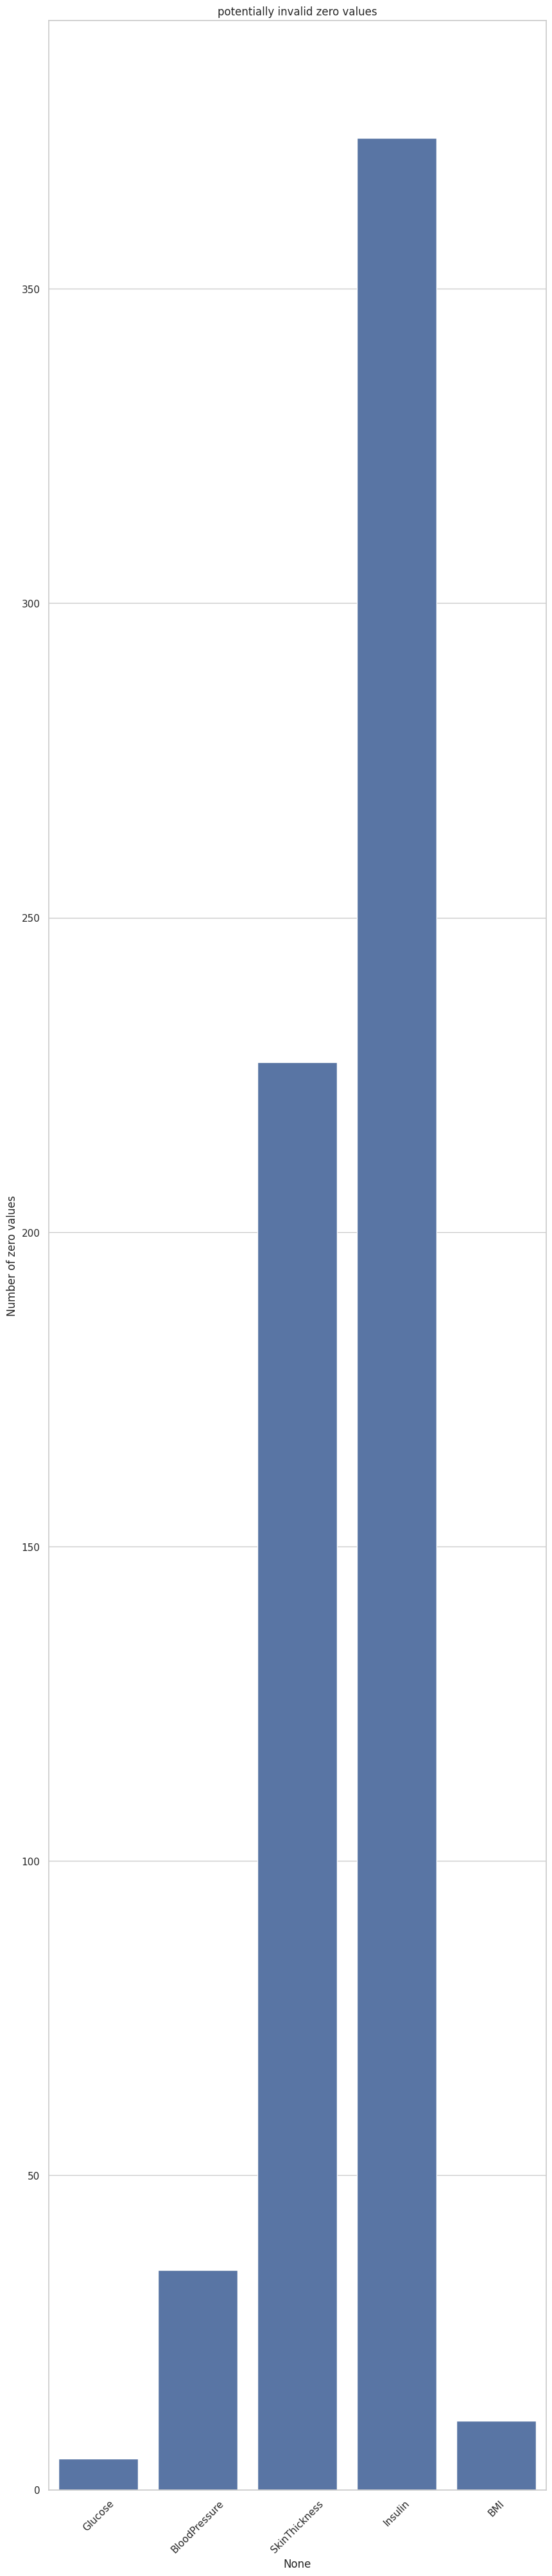

In [19]:
plt.figure(figsize=(10,50))
sns.barplot(x=zero_counts.index,y=zero_counts.values)

plt.xticks(rotation=45)
plt.ylabel("Number of zero values")
plt.title("potentially invalid zero values")

plt.show()


In [20]:
df_clean = df.copy ()

df_clean[zero_columns] = df_clean[zero_columns].replace(0,np.nan)

print("Missing values after replacing invalid zeros:")
print(df_clean.isnull().sum())

Missing values after replacing invalid zeros:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


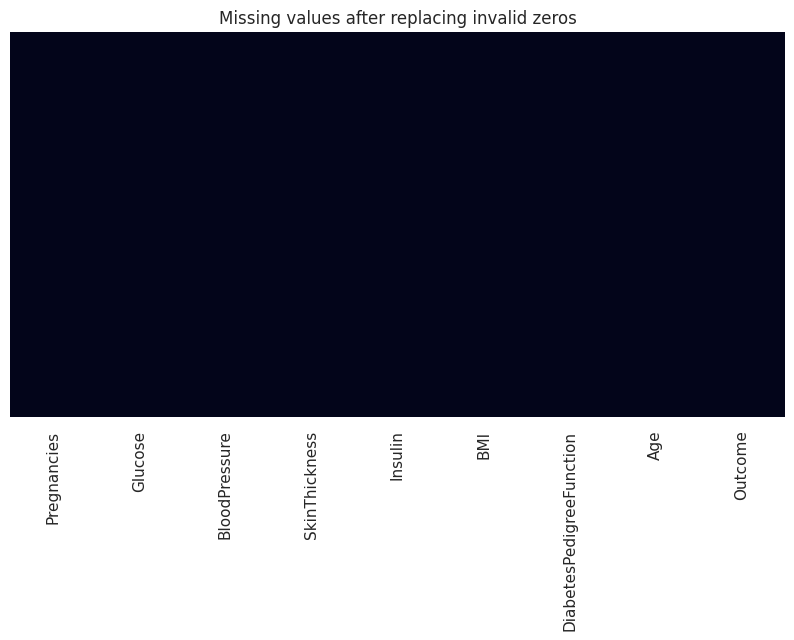

In [21]:
plt.figure(figsize=(10,5))
sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing values after replacing invalid zeros")
plt.show()

In [22]:
for col in zero_columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

print("Total missing values in df_clean:")
print(df_clean.isnull().sum().sum())

Total missing values in df_clean:
0


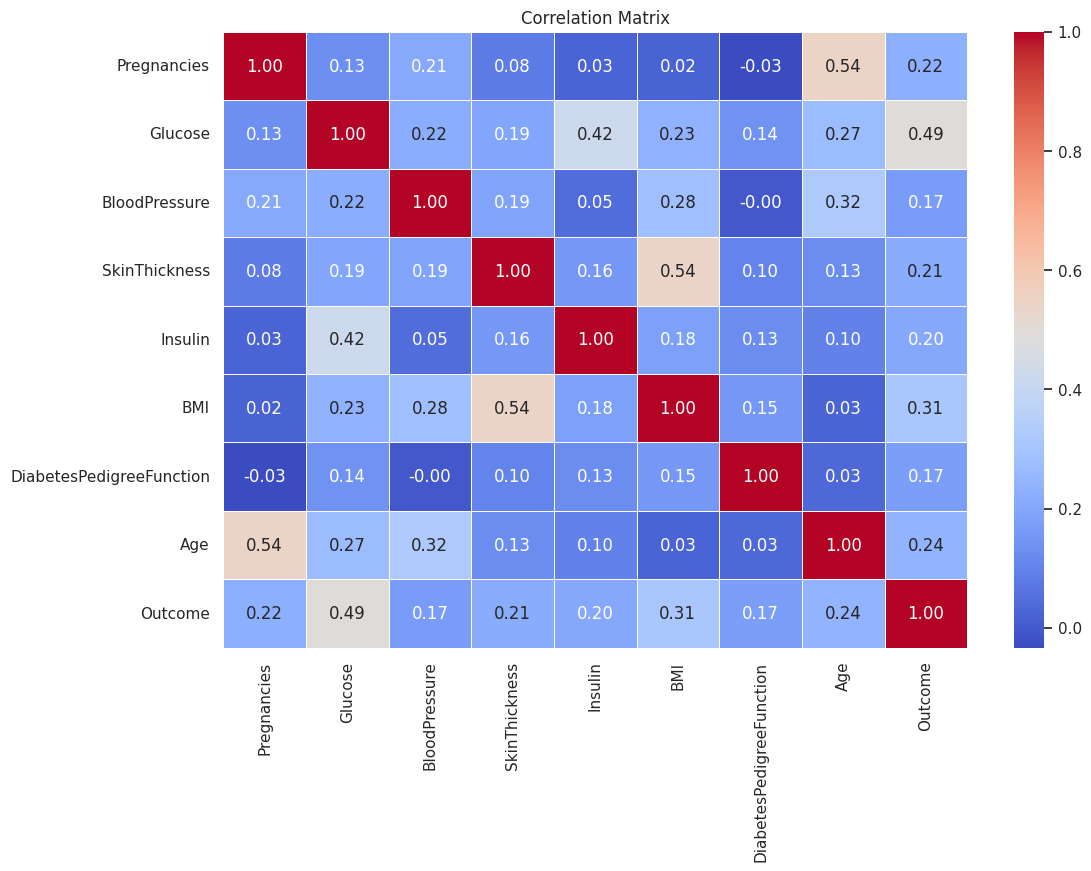

In [23]:
plt.figure(figsize=(12,8))

correlation= df_clean.corr()

sns.heatmap(correlation,annot=True,fmt=".2f",cmap="coolwarm",linewidths=0.5)
plt.title("Correlation Matrix")
plt.show()

In [24]:
target_corr = (df_clean.corr()["Outcome"].drop("Outcome").sort_values())
print(target_corr)

BloodPressure               0.165723
DiabetesPedigreeFunction    0.173844
Insulin                     0.203790
SkinThickness               0.214873
Pregnancies                 0.221898
Age                         0.238356
BMI                         0.312038
Glucose                     0.492782
Name: Outcome, dtype: float64


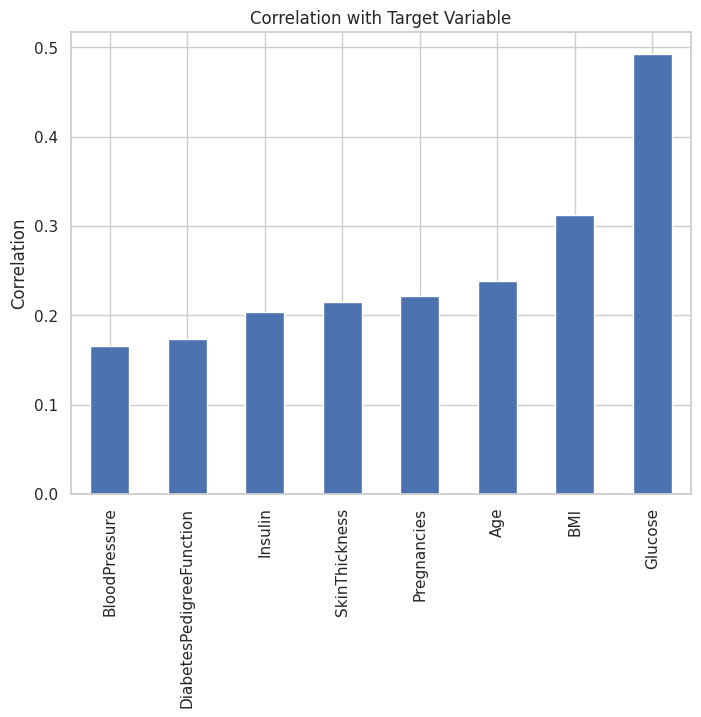

In [25]:
plt.figure(figsize=(8,6))

target_corr.plot(kind="bar")

plt.title("Correlation with Target Variable")
plt.ylabel("Correlation")

plt.show()

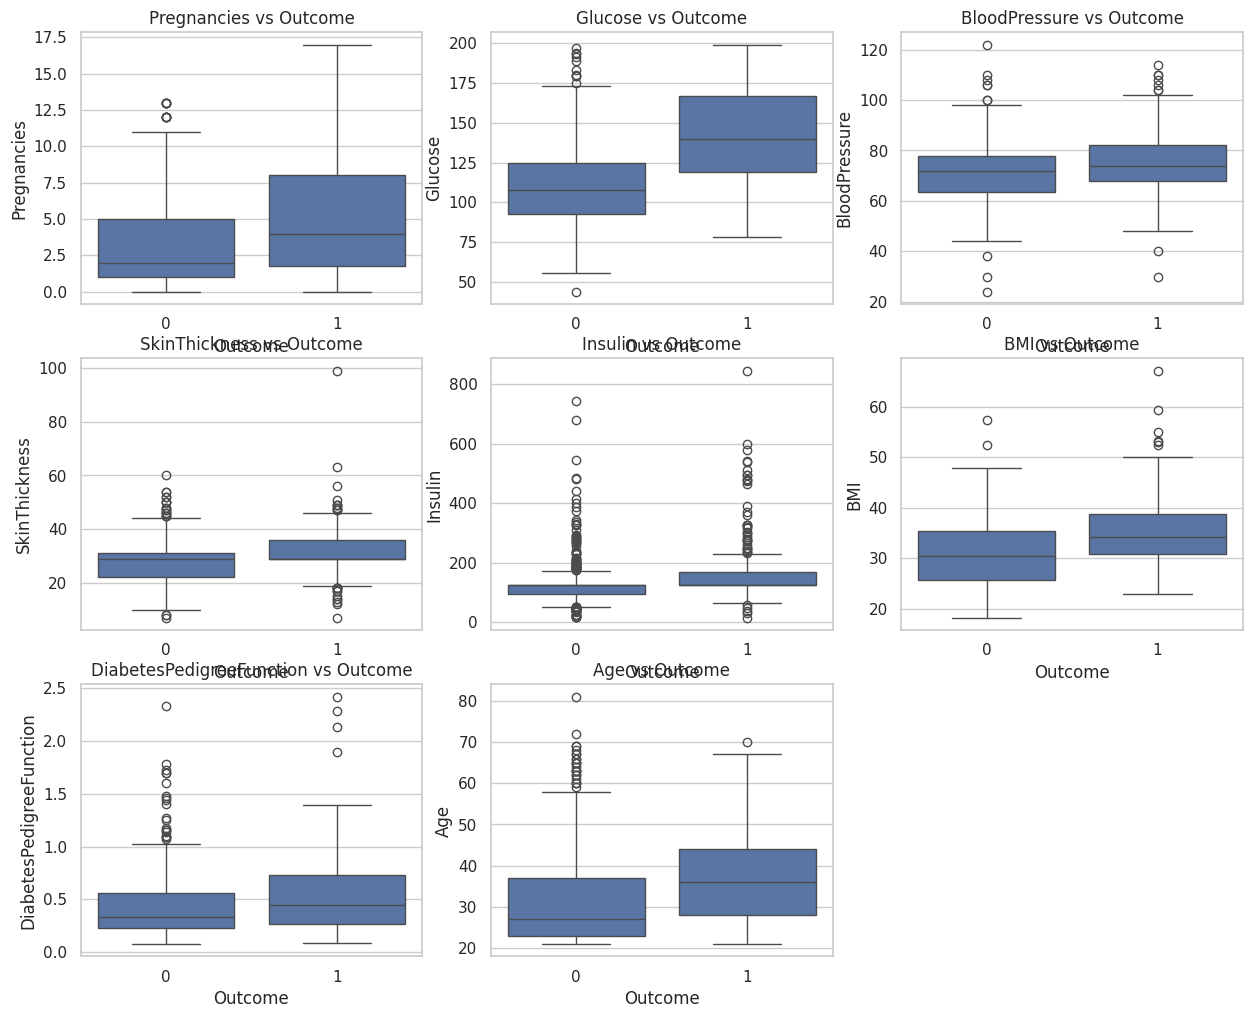

In [26]:
plt.figure(figsize=(15,12))

for i, col in enumerate (features, 1):

  plt.subplot(3,3,i)

  sns.boxplot(data=df_clean,x="Outcome",y=col)

  plt.title(f"{col} vs Outcome")

  plt.tight_layout

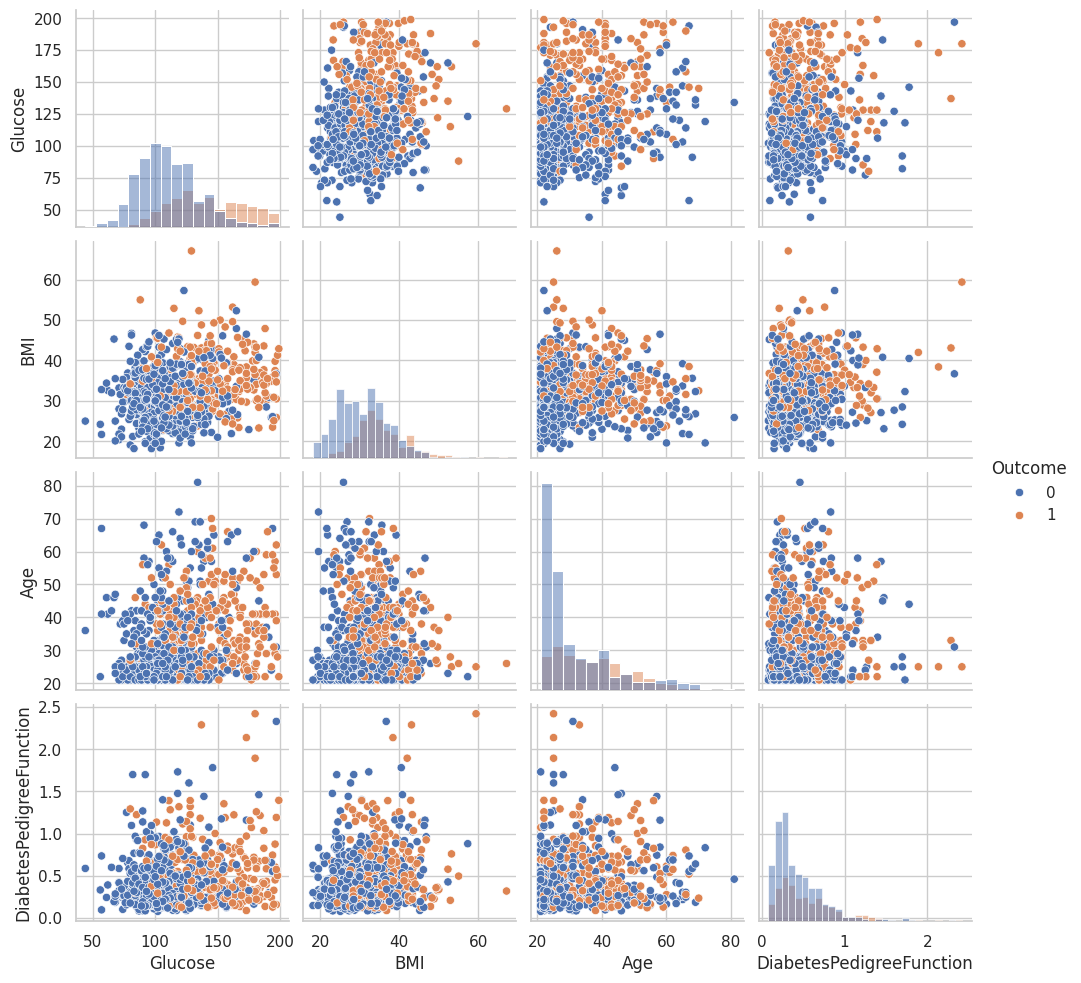

In [27]:
selected_features = ["Glucose","BMI","Age","DiabetesPedigreeFunction","Outcome"]

sns.pairplot(df_clean[selected_features],hue="Outcome",diag_kind="hist")
plt.show()

In [28]:
X = df_clean.drop("Outcome",axis=1)
y = df_clean["Outcome"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (768, 8)
y shape: (768,)


In [29]:
X = df_clean.drop("Outcome", axis=1)
y = df_clean["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data split and scaling updated with fully imputed data.")

Data split and scaling updated with fully imputed data.


In [30]:
print("traning distrinution:")
print(y_train.value_counts(normalize=True))

print("\nTesting  distribution:")
print(y_test.value_counts(normalize=True))

traning distrinution:
Outcome
0    0.653094
1    0.346906
Name: proportion, dtype: float64

Testing  distribution:
Outcome
0    0.642857
1    0.357143
Name: proportion, dtype: float64


In [31]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Scaling completed with clean data")

Scaling completed with clean data


In [32]:
scaler.fit_transform(X_test)

array([[ 0.49124165, -0.72667791, -1.2442565 , ...,  0.17113929,
        -0.17094071,  0.66661154],
       [-0.63368347, -0.28534901,  0.16468101, ...,  0.42819187,
        -1.08608042, -1.07335756],
       [-0.63368347, -0.41144298, -0.74698444, ..., -0.3127244 ,
        -1.05362866, -1.07335756],
       ...,
       [ 1.05370422, -0.82124838, -0.08395502, ...,  0.59452001,
         0.00754398,  1.77386461],
       [-0.63368347,  0.78644972, -0.24971238, ..., -0.73610513,
        -0.47274211, -0.44064153],
       [ 1.05370422, -1.48324172, -0.24971238, ...,  0.36770891,
         0.72148276,  0.35025352]])

In [33]:

scaler.transform(X_test)

array([[ 0.49124165, -0.72667791, -1.2442565 , ...,  0.17113929,
        -0.17094071,  0.66661154],
       [-0.63368347, -0.28534901,  0.16468101, ...,  0.42819187,
        -1.08608042, -1.07335756],
       [-0.63368347, -0.41144298, -0.74698444, ..., -0.3127244 ,
        -1.05362866, -1.07335756],
       ...,
       [ 1.05370422, -0.82124838, -0.08395502, ...,  0.59452001,
         0.00754398,  1.77386461],
       [-0.63368347,  0.78644972, -0.24971238, ..., -0.73610513,
        -0.47274211, -0.44064153],
       [ 1.05370422, -1.48324172, -0.24971238, ...,  0.36770891,
         0.72148276,  0.35025352]])

In [34]:
comparsion = pd.DataFrame({
    "original Mean":X_train.mean(),
    "Original std":X_train.std(),
    "Scaled Mean":X_train_scaled.mean(axis=0),
    "Scaled std":X_train_scaled.std(axis=0)
})

display(comparsion)

,original Mean,Original std,Scaled Mean,Scaled std
Pregnancies,3.742671,3.313264,1.735854e-17,1.0
Glucose,121.807818,30.105181,9.836504e-17,1.0
BloodPressure,72.229642,12.099278,-1.157236e-17,1.0
SkinThickness,28.711726,8.411906,1.417614e-16,1.0
Insulin,140.477199,88.200972,-1.432079e-16,1.0
BMI,32.351629,6.935519,-3.703154e-16,1.0
DiabetesPedigreeFunction,0.469168,0.336847,1.562268e-16,1.0
Age,32.907166,11.503437,-3.761016e-17,1.0


In [35]:

K= 5

In [36]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

print("kNN model training successful!")

kNN model training successful!


In [37]:
y_pred = knn.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
print(f"kNN Model Accuracy: {accuracy:.4f}")

kNN Model Accuracy: 0.7208


In [38]:
y_pred_train = knn.predict(X_train_scaled)
print("predications")

predications
